# 02 — Exploratory Data Analysis

**Research problem:** how do advertised prices, property characteristics and
review activity differ across the ten Airbnb markets?

**Currency rule:** raw price distributions are shown per city in local currency.
Cross-city comparisons use a dimensionless price index (price ÷ city median).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

from src.eda import load, run
from IPython.display import Image, display

df = load()
print(f"{len(df):,} listings with a usable price across {df['city'].nunique()} cities")
display(df[["price", "price_usd", "accommodates", "review_count"]].describe().round(1))

279,599 listings with a usable price across 10 cities


,price,price_usd,accommodates,review_count
count,279599.0,279599.0,279599.0,279599.0
mean,609.0,112.6,3.3,19.2
std,3442.5,400.6,2.1,43.4
min,1.0,0.1,1.0,0.0
25%,75.0,35.0,2.0,0.0
50%,150.0,66.8,2.0,3.0
75%,475.0,112.1,4.0,16.0
max,625216.0,112520.1,16.0,891.0


## Market overview

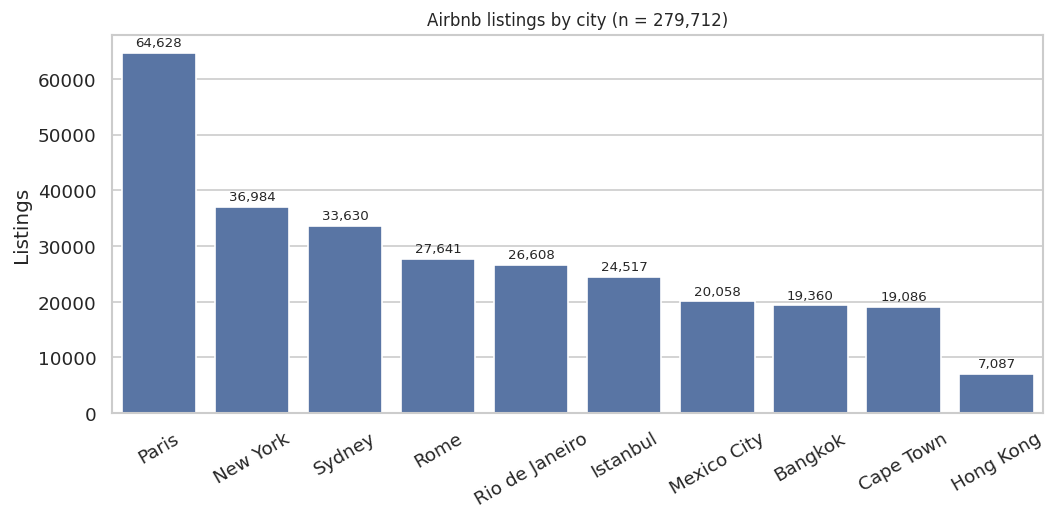

,city,currency,listings,median_price_local,mean_price_local,median_price_usd,mean_price_usd,p90_price_usd,median_accommodates,pct_entire_place,median_rating,rated_share,median_reviews,mean_reviews,pct_with_reviews,median_response_rate,mean_response_rate,median_acceptance_rate,superhost_share
0,Paris,EUR,64020,80.0,101.371899,89.016000,112.796512,203.624100,2.0,85.793502,95.0,74.539206,5.0,18.849688,76.382381,1.0,0.858893,0.97,12.561699
1,New York,USD,36619,98.0,125.412982,98.000000,125.412982,241.000000,2.0,52.235178,97.0,72.656271,4.0,23.058740,74.578771,1.0,0.886130,0.94,18.867255
2,Sydney,AUD,33293,120.0,191.029406,82.310443,131.030958,274.368142,2.0,60.334004,97.0,66.917971,2.0,14.425945,70.567387,1.0,0.878631,0.96,12.161716
3,Rome,EUR,27367,65.0,84.751379,72.325500,94.302860,166.905000,3.0,62.304966,96.0,75.912595,9.0,40.553038,77.041693,1.0,0.875032,1.00,25.888844
4,Rio de Janeiro,BRL,26341,279.0,502.977184,50.211607,90.520762,196.347178,4.0,72.324513,98.0,60.980980,2.0,12.256596,63.004442,1.0,0.834708,0.94,17.072245
5,Istanbul,TRY,24271,250.0,374.380907,4.977214,7.453496,14.931642,2.0,50.541799,96.0,46.087924,0.0,7.974084,47.888427,1.0,0.830744,1.00,13.266862
6,Mexico City,MXN,19857,651.0,919.224404,34.888606,49.263376,97.484445,2.0,52.434910,97.0,72.488291,5.0,23.965352,73.455205,1.0,0.893604,1.00,31.958503
7,Bangkok,THB,19166,1090.0,1645.880726,32.353696,48.853509,96.467442,2.0,54.852343,96.0,58.014192,1.0,14.767453,59.355108,1.0,0.851199,1.00,20.098090
8,Cape Town,ZAR,18895,1050.0,1964.440752,63.390701,118.597407,271.674435,3.0,73.971950,98.0,70.881185,3.0,15.983541,72.363059,1.0,0.907572,0.95,24.080445
9,Hong Kong,HKD,7017,380.0,611.048169,48.434787,77.884178,152.671546,2.0,36.482827,93.0,53.356135,1.0,19.056292,54.610232,1.0,0.834180,0.88,18.198660


In [2]:
paths = run(df)
display(Image(paths["listings_by_city"]))
display(pd.read_csv("../outputs/tables/eda_city_summary.csv"))

Paris is the largest market in the extract (64,690 listings), Hong Kong the
smallest (7,087). Listing counts describe the supplied extract, not the live
market.

## Price distributions — local currency, one panel per city

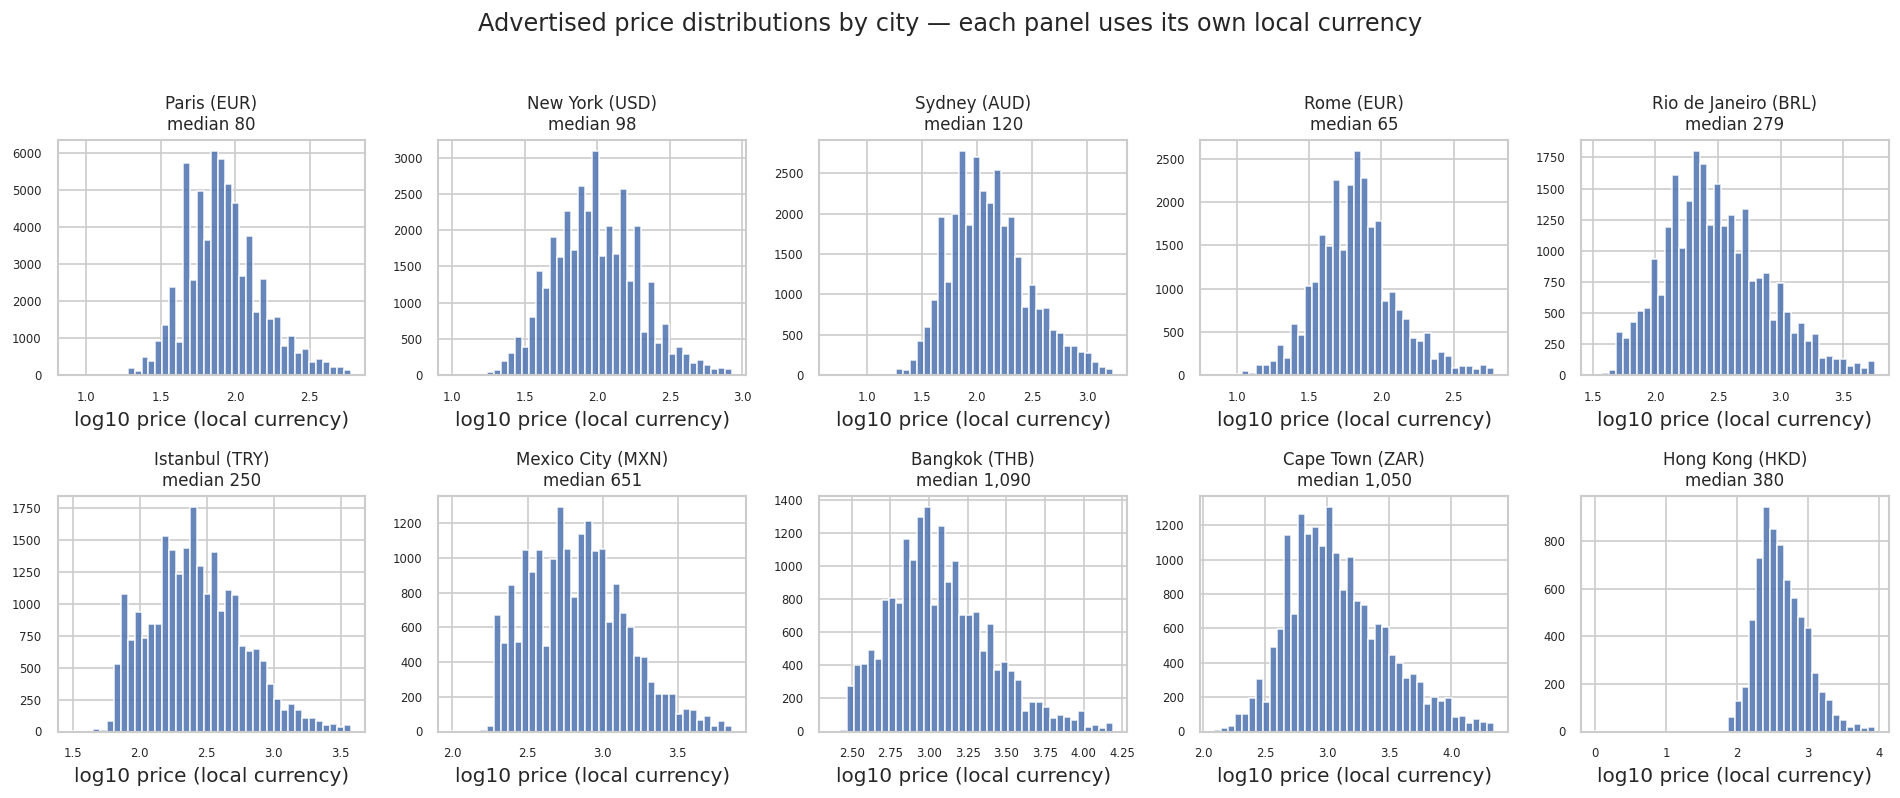

In [3]:
display(Image(paths["price_distribution"]))

All ten distributions are right-skewed with a long upper tail. Because the
panels use different currencies, only the *shape* is comparable; levels are not.
This is why the analysis uses within-city tests and relative indices.

## Room type and price

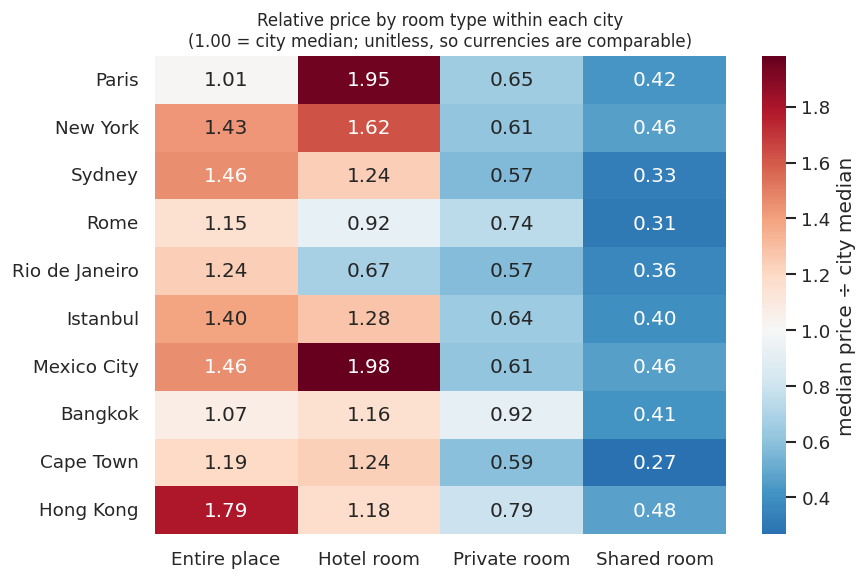

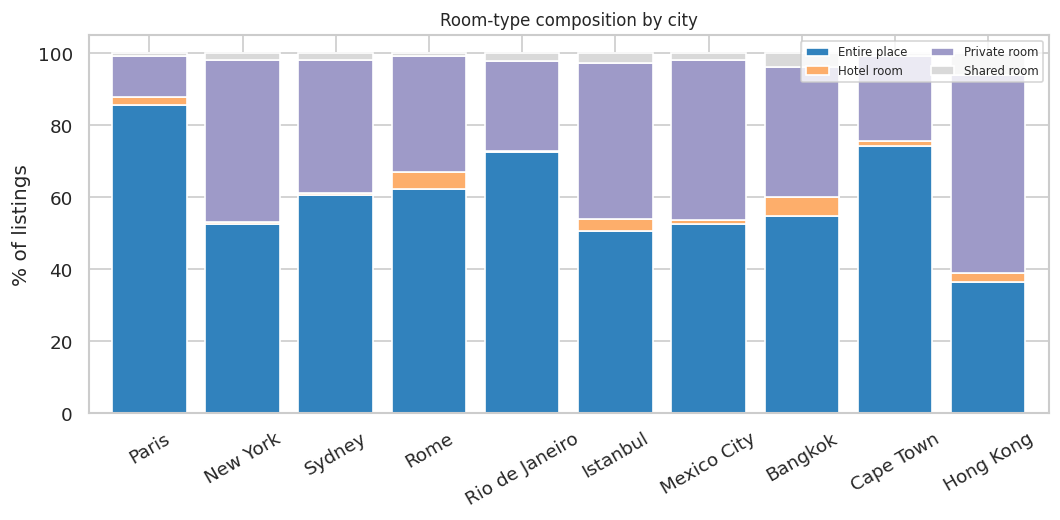

,city,room_type,n,median_price_local,median_price_usd,median_rating
0,Paris,Entire place,54925,81.0,90.128700,95.0
1,Paris,Hotel room,1252,156.0,173.581200,94.0
2,Paris,Private room,7420,52.0,57.860400,96.0
3,Paris,Shared room,423,34.0,37.831800,93.0
4,New York,Entire place,19128,140.0,140.000000,97.0
5,New York,Hotel room,258,159.0,159.000000,91.0
6,New York,Private room,16555,60.0,60.000000,96.0
7,New York,Shared room,678,45.0,45.000000,95.0
8,Sydney,Entire place,20087,175.0,120.036062,97.0
9,Sydney,Hotel room,233,149.0,102.202133,93.0


In [4]:
display(Image(paths["price_index_heatmap"]))
display(Image(paths["roomtype_mix"]))
display(pd.read_csv("../outputs/tables/eda_roomtype_by_city.csv"))

`Entire place` sits above each city's median everywhere; private and shared
rooms sit below it. The heatmap is unitless, so the pattern is comparable even
though the underlying prices are not.

## Property types

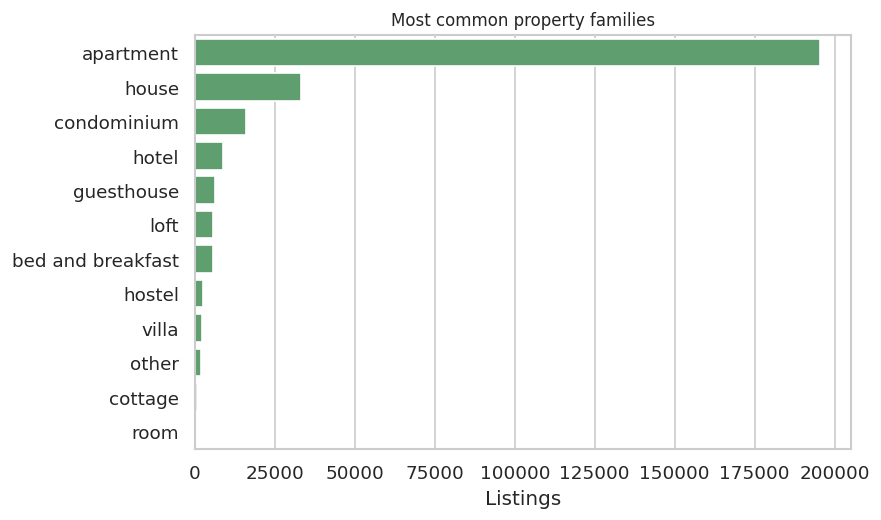

In [5]:
display(Image(paths["property_family"]))

## Capacity and relative price

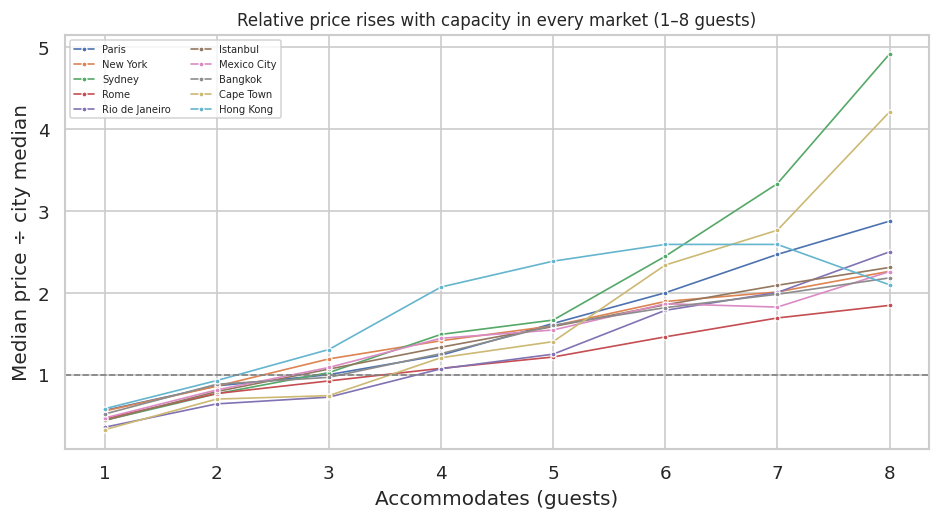

In [6]:
display(Image(paths["capacity_price"]))

Relative price rises monotonically with capacity up to roughly 6–8 guests and
then flattens or falls as large listings are discounted per guest. This is a
strong candidate for the price model and a hypothesis test.

## Review activity

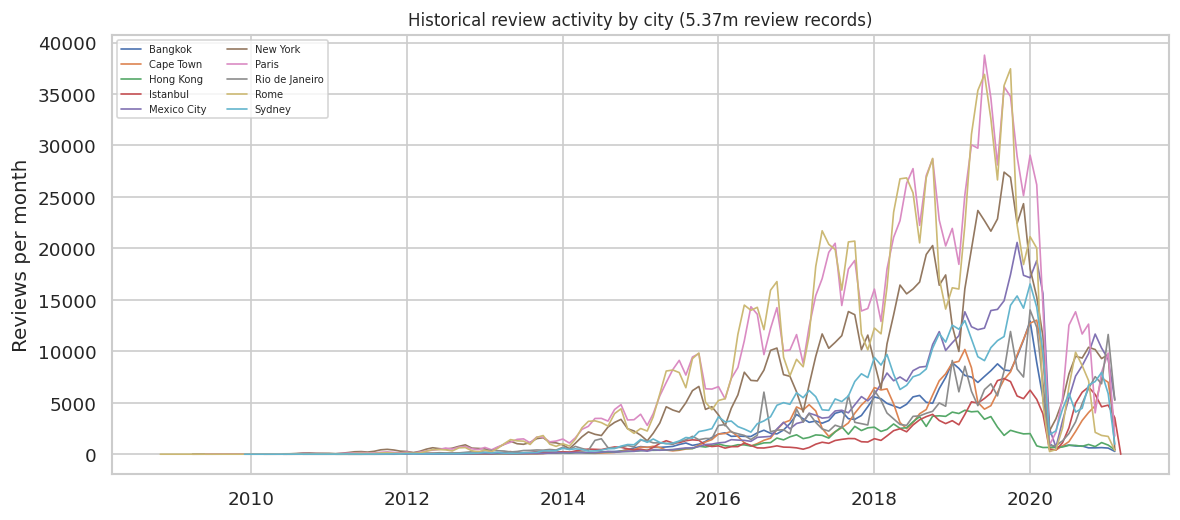

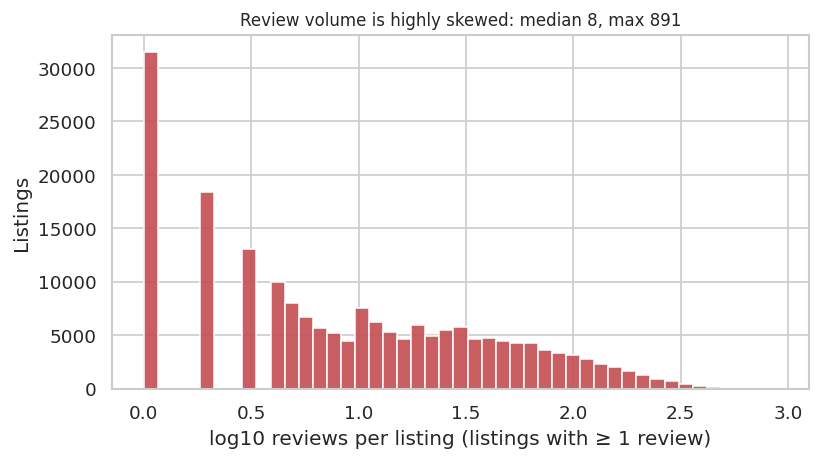

,city,listings,listings_with_reviews,total_reviews,median_reviews,mean_reviews,p90_reviews,reviews_per_listing
0,Paris,64628,49228,1213727,5.0,18.780204,50.0,18.780204
1,New York,36984,27489,847727,4.0,22.921453,70.0,22.921453
2,Sydney,33630,23599,482552,2.0,14.348855,40.0,14.348855
3,Rome,27641,21205,1113360,8.0,40.279295,126.0,40.279295
4,Rio de Janeiro,26608,16657,323274,2.0,12.149504,34.0,12.149504
5,Istanbul,24517,11673,194013,0.0,7.913407,20.0,7.913407
6,Mexico City,20058,14679,477584,5.0,23.810151,72.0,23.810151
7,Bangkok,19360,11440,284342,1.0,14.687087,42.1,14.687087
8,Cape Town,19086,13718,302336,3.0,15.840721,47.0,15.840721
9,Hong Kong,7087,3868,134228,1.0,18.940031,58.0,18.940031


In [7]:
display(Image(paths["review_activity"]))
display(Image(paths["reviews_per_listing"]))
display(pd.read_csv("../outputs/tables/eda_review_summary.csv"))

Review volume grew strongly until the 2020 disruption and recovered unevenly.
Review counts are cumulative and confounded with listing age, so they cannot be
read as current demand. Listings without reviews are included as zeros in the
aggregate review analysis and excluded from rating analysis.

## Ratings and host indicators

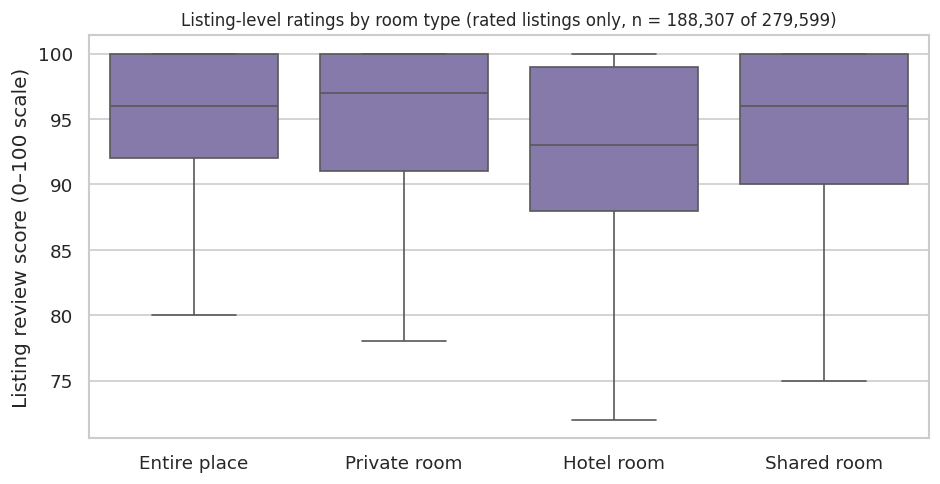

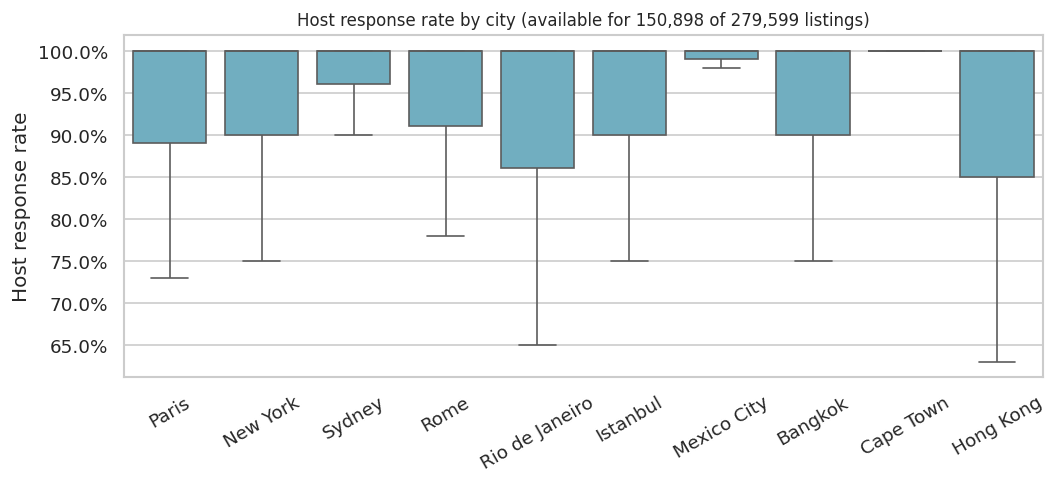

In [8]:
display(Image(paths["ratings_roomtype"]))
display(Image(paths["host_response"]))

Ratings are compressed near the top of the scale, which limits how much
separation any group comparison can show. Host response rate is missing for
~46% of listings; the boxplots describe the listings where it is reported.

## What this EDA does not show

- It does not measure occupancy, bookings or revenue.
- It does not measure guest sentiment: there is no review text and no per-review rating.
- It does not establish causation between any attribute and price.